# ✍️ Handwritten Digit Recognition — End-to-End Deep Learning Project

**A beginner-friendly, step-by-step image classification project**

In this notebook we will build a deep learning model that recognizes handwritten digits from **0 to 9** based on handwritten digit images. The model will learn to classify each input image into one of the **10 digit classes: 0, 1, 2, 3, 4, 5, 6, 7, 8, and 9**.

We will go through the **complete deep learning workflow**:

1. Load & explore the raw handwritten digit dataset
2. Basic checks and clean the dataset
3. Analyze the number of images available for each digit class
4. Preprocess the images by resizing and normalizing pixel values
5. Visualize sample images from digits **0–9**
6. Handle missing, duplicate, or corrupted images if present
7. Split the dataset into **training, validation, and testing** sets
8. Build a **CNN-based image classification model**
9. Train the CNN model and monitor training/validation accuracy and loss
10. Apply **Data Augmentation** to improve model generalization
11. Tune hyperparameters such as **learning rate, batch size, number of epochs, dropout, and optimizer**
12. Evaluate the model using **accuracy, precision, recall, F1-score, confusion matrix, and classification report**
13. Test the model by providing new handwritten digit images
14. After running all the models, compare their performance
15. Choose the model with the **best validation/test performance** and select it as the final model
16. Save the final trained model as a `.h5` or `.keras` file
17. Reload the saved model and make a prediction on a new handwritten digit image to prove it works
18. Display the predicted digit and prediction confidence
19. Build a UI using **Streamlit** where users can upload a handwritten digit image and get the predicted digit **(optional)**

> 💡 Every step includes comments explaining **why** we do it, not just how — this notebook is written for someone new to deep learning and image classification.


In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("olafkrastovski/handwritten-digits-0-9")

print("Path to dataset files:", path)

100%|██████████| 66.7M/66.7M [00:00<00:00, 79.6MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/olafkrastovski/handwritten-digits-0-9/versions/2


In [2]:
import os
print(os.listdir(path))

['0', '4', '8', '1', '2', '5', '9', '3', '7', '6']


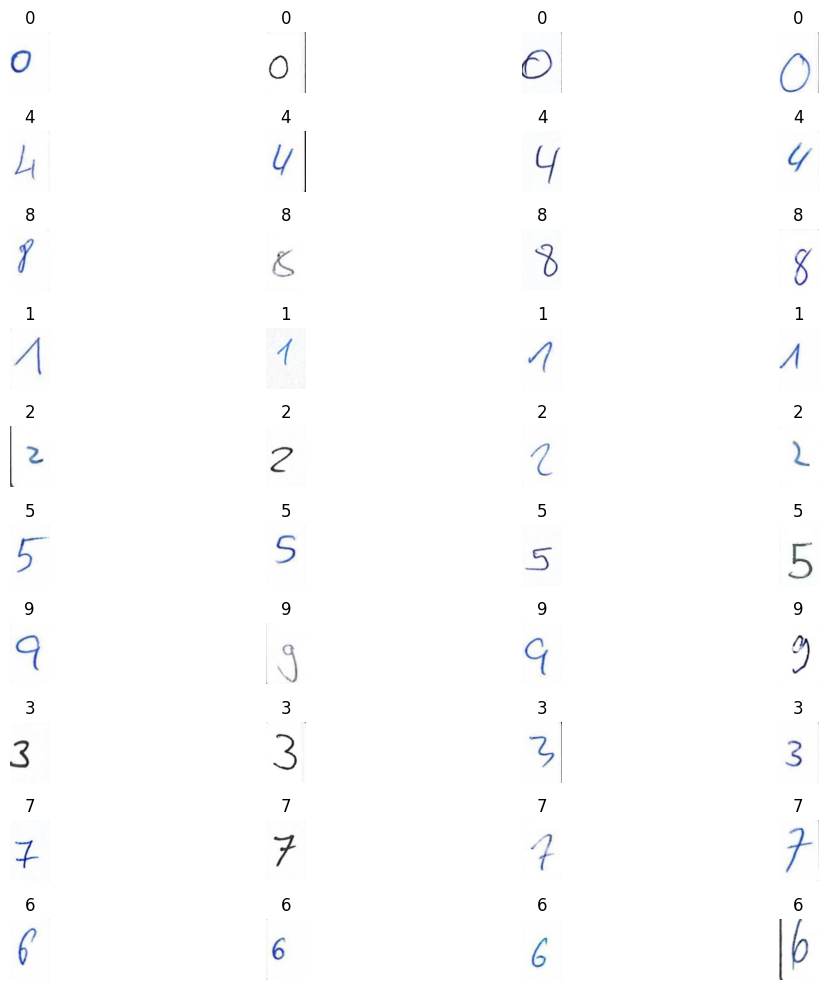

In [5]:
import matplotlib.pyplot as plt
from PIL import Image

#base_path = os.path.join(path, "/kaggle/input/handwritten-digits-0-9")
base_path = path
plt.figure(figsize=(12, 10))
i=1

for class_name in os.listdir(base_path):
  class_path = os.path.join(base_path, class_name)
  #print(class_path)

  if os.path.isdir(class_path):
        images = os.listdir(class_path)[:4]

        for img_name in images:
            img_path = os.path.join(class_path, img_name)
            img = Image.open(img_path)

            plt.subplot(10,4, i)  # 5 classes × 3 images
            plt.imshow(img)
            plt.title(class_name)
            plt.axis('off')

            i += 1

plt.tight_layout()
plt.show()

**Number of images in each folder**

In [6]:
base_path = path

for class_name in os.listdir(base_path):
    class_path = os.path.join(base_path, class_name)

    if os.path.isdir(class_path):
        count = len(os.listdir(class_path))
        print(class_name, ":", count)

0 : 2236
4 : 2179
8 : 2085
1 : 2241
2 : 2233
5 : 2126
9 : 2016
3 : 2202
7 : 2116
6 : 2121


**Create dataframe with image and label**

In [7]:
import pandas as pd

base_path = path

data = []

for label in os.listdir(base_path):
    class_path = os.path.join(base_path, label)

    if os.path.isdir(class_path):
        for img in os.listdir(class_path):
            img_path = os.path.join(class_path, img)
            data.append([img_path, label])

df = pd.DataFrame(data, columns=["image_path", "label"])
df

,image_path,label
0,/root/.cache/kagglehub/datasets/olafkrastovski...,0
1,/root/.cache/kagglehub/datasets/olafkrastovski...,0
2,/root/.cache/kagglehub/datasets/olafkrastovski...,0
3,/root/.cache/kagglehub/datasets/olafkrastovski...,0
4,/root/.cache/kagglehub/datasets/olafkrastovski...,0
...,...,...
21550,/root/.cache/kagglehub/datasets/olafkrastovski...,6
21551,/root/.cache/kagglehub/datasets/olafkrastovski...,6
21552,/root/.cache/kagglehub/datasets/olafkrastovski...,6
21553,/root/.cache/kagglehub/datasets/olafkrastovski...,6


**Shuffle data**

In [8]:
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

In [9]:
df

,image_path,label
0,/root/.cache/kagglehub/datasets/olafkrastovski...,1
1,/root/.cache/kagglehub/datasets/olafkrastovski...,5
2,/root/.cache/kagglehub/datasets/olafkrastovski...,4
3,/root/.cache/kagglehub/datasets/olafkrastovski...,5
4,/root/.cache/kagglehub/datasets/olafkrastovski...,7
...,...,...
21550,/root/.cache/kagglehub/datasets/olafkrastovski...,5
21551,/root/.cache/kagglehub/datasets/olafkrastovski...,5
21552,/root/.cache/kagglehub/datasets/olafkrastovski...,8
21553,/root/.cache/kagglehub/datasets/olafkrastovski...,0


In [10]:
train_size = int(0.7 * len(df))
val_size = int(0.15 * len(df))
test_size = int(0.15*len(df))
print(f"train_size:{train_size} -----val_size:{val_size}----test_size:{test_size}")

train_data = df.iloc[:train_size]
# df.iloc[:,52500]
val_data = df.iloc[train_size:train_size + val_size]
# df.iloc[52500:52500+11250]
test_data = df.iloc[train_size + val_size:]
# df.iloc[52500+11250:]

# Display the sizes of each set
print(f'Training set size: {len(train_data)}')
print(f'Validation set size: {len(val_data)}')
print(f'Test set size: {len(test_data)}')

train_size:15088 -----val_size:3233----test_size:3233
Training set size: 15088
Validation set size: 3233
Test set size: 3234


In [11]:
image_path = df["image_path"][0]
image = Image.open(image_path)
width, height = image.size
print(f"height,width:{height,width}")

height,width:(140, 90)


In [12]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [13]:
batch_size = 32
img_height = 128
img_width = 128

In [14]:
# Normalization
data_generator = ImageDataGenerator(
    rescale=1.0/255, # Normalization: Pixel values go from 0–255 → 0–1
    rotation_range=40, #Randomly rotates image up to ±40 degrees
    width_shift_range=0.2, #Moves image left/right by 20%
    height_shift_range=0.2, # Moves image up/down by 20%
    shear_range=0.2, # Slants the image (like pushing it sideways)
    zoom_range=0.2, # Zoom in/out randomly
    horizontal_flip=True, #Flips image left ↔ right
    fill_mode='nearest' #This fills those gaps using nearest pixels
)

In [15]:
# train data
train_generator = data_generator.flow_from_dataframe(
  dataframe=train_data,
  x_col="image_path",
  y_col="label",
  target_size=(img_height, img_width),
  batch_size=batch_size,
  class_mode="categorical",
  shuffle=True,
  seed=42
)

Found 15088 validated image filenames belonging to 10 classes.


In [16]:
# test generator
test_generator = data_generator.flow_from_dataframe(
  dataframe=test_data,
  x_col="image_path",
  y_col="label",
  target_size=(img_height, img_width),
  batch_size=batch_size,
  class_mode="categorical",
  shuffle=True,
  seed=42
)

Found 3234 validated image filenames belonging to 10 classes.


In [17]:
# validation generator
validation_generator = data_generator.flow_from_dataframe(
  dataframe=val_data,
  x_col="image_path",
  y_col="label",
  target_size=(img_height, img_width),
  batch_size=batch_size,
  class_mode="categorical",
  shuffle=True,
  seed=42
)

Found 3233 validated image filenames belonging to 10 classes.


In [18]:
for image_batch, labels_batch in train_generator:
    print(f"Train Shape: {image_batch.shape} (Batches = {len(train_generator)})")
    print(f"Train Label Shape: {labels_batch.shape}\n")
    break

for image_batch, labels_batch in validation_generator:
    print(f"Validation Shape: {image_batch.shape} (Batches = {len(validation_generator)})")
    print(f"Validation Label Shape: {labels_batch.shape}\n")
    break

for image_batch, labels_batch in test_generator:
    print(f"Test Shape: {image_batch.shape} (Batches = {len(test_generator)})")
    print(f"Test Label Shape: {labels_batch.shape}\n")
    break

Train Shape: (32, 128, 128, 3) (Batches = 472)
Train Label Shape: (32, 10)

Validation Shape: (32, 128, 128, 3) (Batches = 102)
Validation Label Shape: (32, 10)

Test Shape: (32, 128, 128, 3) (Batches = 102)
Test Label Shape: (32, 10)



In [19]:
from tensorflow.keras import layers,models
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import categorical_crossentropy

In [20]:
n_classes= 10
cnn_model = models.Sequential([
    layers.Input(shape=(128,128,3)),
    layers.Conv2D(32,kernel_size= (3,3),activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64,kernel_size= (3,3),activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64,kernel_size= (3,3),activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64,activation='relu'),
    layers.Dense(n_classes,activation='softmax')])

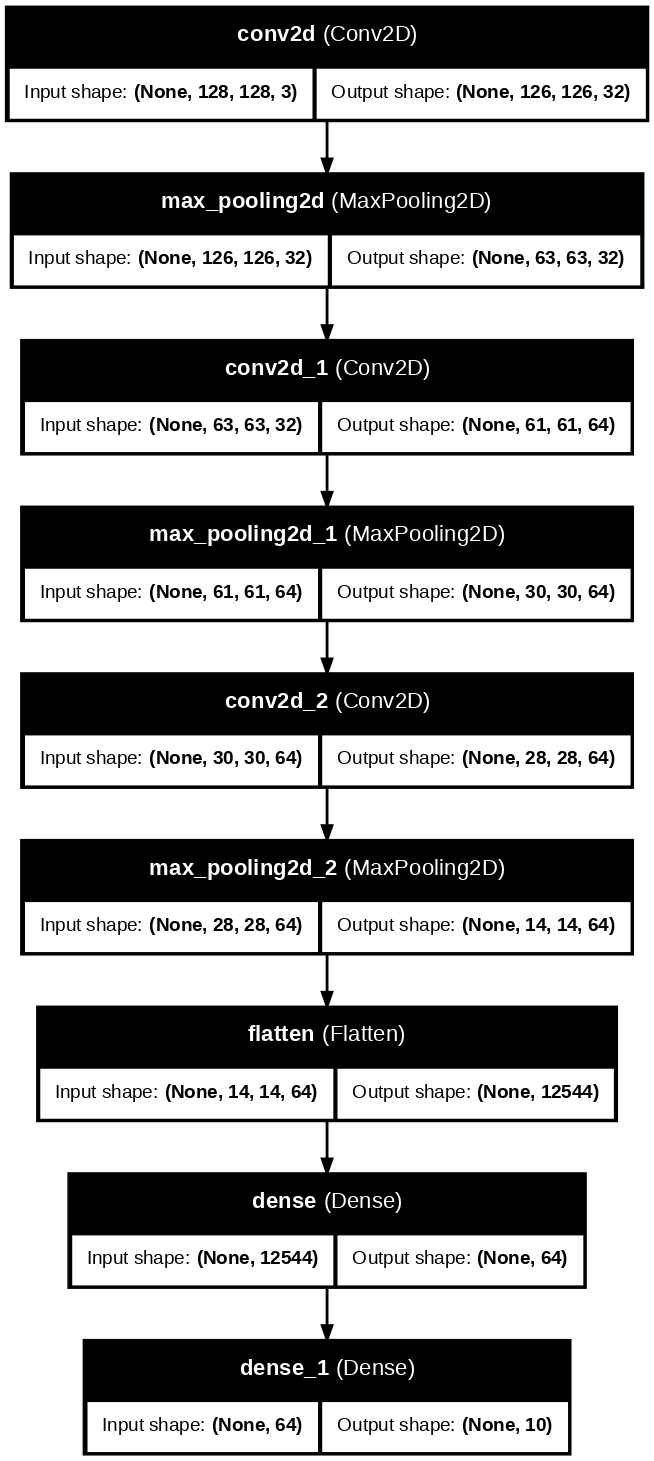

In [21]:
from tensorflow.keras.utils import plot_model
plot_model(cnn_model, to_file='model_plot.png', show_shapes=True, show_layer_names=True, dpi=100, expand_nested=True)

In [25]:
cnn_model.compile(loss=categorical_crossentropy,
                  optimizer=Adam(),
                  metrics=['accuracy'])

In [27]:
Cnn = cnn_model.fit(train_generator,epochs=20,validation_data=validation_generator,verbose=1)

Epoch 1/20
472/472 ━━━━━━━━━━━━━━━━━━━━ 541s 1s/step - accuracy: 0.2894 - loss: 1.9794 - val_accuracy: 0.3347 - val_loss: 1.8619
Epoch 2/20
472/472 ━━━━━━━━━━━━━━━━━━━━ 544s 1s/step - accuracy: 0.3996 - loss: 1.7028 - val_accuracy: 0.4550 - val_loss: 1.5979
Epoch 3/20
472/472 ━━━━━━━━━━━━━━━━━━━━ 551s 1s/step - accuracy: 0.4895 - loss: 1.4716 - val_accuracy: 0.5444 - val_loss: 1.3581
Epoch 4/20
472/472 ━━━━━━━━━━━━━━━━━━━━ 539s 1s/step - accuracy: 0.5712 - loss: 1.2651 - val_accuracy: 0.5979 - val_loss: 1.1916
Epoch 5/20
472/472 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6190 - loss: 1.1489

KeyboardInterrupt: 

In [ ]:
train_loss, train_accuracy = cnn_model.evaluate(train_generator, verbose=1)
print(f'Training accuracy: {train_accuracy:.4f}')

# Evaluate on the test data
test_loss, test_accuracy = cnn_model.evaluate(test_generator, verbose=1)
print(f'Test accuracy: {test_accuracy:.4f}')

In [ ]:
# Retrieve metrics from the training history
acc = Cnn.history['accuracy']
val_acc = Cnn.history['val_accuracy']
loss = Cnn.history['loss']
val_loss = Cnn.history['val_loss']

epochs_range = range(1, len(acc) + 1)

# Plot accuracy
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy for CNN')
plt.legend()

# Plot loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss for CNN')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
from tensorflow.keras.preprocessing import image
import numpy as np

img_path = "three.jpg"

# Load image
img = image.load_img(img_path, target_size=(128, 128))  # same as training

# Convert to array
img_array = image.img_to_array(img)

# Normalize
img_array = img_array / 255.0

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

In [ ]:
prediction = cnn_model.predict(img_array)
prediction

In [ ]:
predicted_class = np.argmax(prediction)

print("Predicted Class:", predicted_class)